# 01 - Improvement experiments (multi-region SCAN + Sentinel-1, 2015-2018)

This notebook reproduces every number in the improvement report. It reads the processed data in
`../data/processed/` and the result tables in `../results/tables/`.

* Set `RERUN = True` to recompute everything from the raw data. That takes about 3-4 h on 2 CPU cores.
  The deep-learning and transfer-learning parts take most of that time.
* With `RERUN = False` it only loads the saved tables and draws the figures. That takes about 1 minute.

**Data.** Public, real data from github.com/kashingtonDC/RZSM:
* SCAN hourly soil moisture, downloaded from the NRCS Report Generator, for about 230 sites
* Sentinel-1 VV/VH, Landsat-8, MODIS LAI and PRISM rain extracted with Earth Engine at each SCAN site

The period is 2015-01 to 2019-01. 84 CONUS sites have at least 20 Sentinel-1 dates with in-situ data,
and 188 sites have daily 5 cm data.

In [1]:
import sys, os
sys.path.insert(0, '../src')
import pandas as pd
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
RERUN = False
TAB = '../results/tables'

## 0. Build the datasets (raw -> processed)

In [2]:
if RERUN:
    import build_dataset; build_dataset.main()
from common import load_anchor
a = load_anchor()
print(a.shape, a.site.nunique(), 'sites')
a.groupby('region').agg(sites=('site','nunique'), samples=('site','size'), mean_sm=('sm_5cm','mean')).round(2)

(8693, 57) 84 sites


,sites,samples,mean_sm
region,,,
N.Rockies&Plains,7,990,17.45
Northeast,1,94,24.45
Northwest,5,468,12.05
South,6,697,17.97
Southwest,43,4270,11.73
West,22,2174,9.82


## 1. Paper protocol vs. honest evaluation (exp1)
The paper-analogue features use the paper's 16-feature design. Landsat-8 indices stand in for Sentinel-2, MODIS LAI stands in for MODIS NDVI/EVI, and slope is not available.
The SAR indices are computed on dB values, as the repo does. Persistence = the lag value itself.

In [3]:
if RERUN:
    import exp1_baselines; exp1_baselines.main()
e1 = pd.read_csv(f'{TAB}/exp1_baselines.csv')
e1[e1.model.isin(['Ensemble','Persistence(prevS1)','Persistence(1d)'])][['protocol','features','model','n','R2','RMSE','ubRMSE','site_median_r','site_median_ubRMSE']].round(3)

,protocol,features,model,n,R2,RMSE,ubRMSE,site_median_r,site_median_ubRMSE
3,random80/20,paper16+lagPrevS1,Ensemble,787,0.800,3.678,3.677,0.805,2.949
4,random80/20,paper16+lagPrevS1,Persistence(prevS1),787,0.737,4.216,4.181,0.765,3.400
8,random80/20,paper16-noLag,Ensemble,787,0.666,4.749,4.748,0.763,3.429
12,leave-stations-out,paper16+lagPrevS1,Ensemble,3933,0.767,3.915,3.915,0.770,3.289
13,leave-stations-out,paper16+lagPrevS1,Persistence(prevS1),3933,0.744,4.103,4.060,0.749,3.578
17,leave-stations-out,paper16-noLag,Ensemble,3933,0.087,7.745,7.731,0.588,4.439
21,temporal(2018),paper16+lagPrevS1,Ensemble,1898,0.699,4.245,4.241,0.690,3.676
22,temporal(2018),paper16+lagPrevS1,Persistence(prevS1),1898,0.697,4.264,4.249,0.685,3.731
26,temporal(2018),paper16-noLag,Ensemble,1898,0.257,6.671,6.495,0.428,5.004
30,leave-one-region-out,paper16+lagPrevS1,Ensemble,3933,0.736,4.167,4.166,0.736,3.543


## 2A. Stronger models: regularised trees vs TempoSAR (Transformer over the S1 history) vs hybrid

In [4]:
if RERUN:
    import exp2_transfer as e2
    lab, full = e2.load_for_deep(); e2.part_a(lab, full)
pd.read_csv(f'{TAB}/exp2a_loso_models.csv')[['model','n','R2','RMSE','ubRMSE','bias','r','site_median_r','site_median_ubRMSE']].round(3)

,model,n,R2,RMSE,ubRMSE,bias,r,site_median_r,site_median_ubRMSE
0,RF,8641,0.205,7.764,7.758,0.299,0.463,0.592,4.818
1,XGB,8641,0.235,7.614,7.605,0.375,0.506,0.621,4.552
2,LGBM,8641,0.221,7.684,7.675,0.377,0.498,0.613,4.644
3,TreeEns,8641,0.237,7.605,7.597,0.350,0.500,0.625,4.531
4,TempoSAR,8641,0.237,7.607,7.585,-0.579,0.492,0.558,5.028
5,MLP(noSeq),8641,0.177,7.899,7.871,-0.666,0.439,0.533,5.104
6,Hybrid,8641,0.278,7.398,7.397,-0.114,0.528,0.619,4.754


## 2B. Transfer learning to a new climate region (pretrain on other regions, fine-tune on 1 / 3 / all target stations)

In [5]:
if RERUN:
    e2.part_b(lab, full)
t = pd.read_csv(f'{TAB}/exp2b_transfer.csv')
t[t.region=='ALL'][['n_ft_sites','method','R2','RMSE','ubRMSE','site_median_r','site_median_ubRMSE']].round(3)

,n_ft_sites,method,R2,RMSE,ubRMSE,site_median_r,site_median_ubRMSE
120,1,ZeroShot-Trees,0.119,8.124,8.111,0.530,4.698
121,1,ZeroShot-Deep,0.149,7.988,7.967,0.511,4.782
122,1,Scratch-Trees,0.054,8.418,8.412,0.424,5.365
123,1,Scratch-Deep,-646.813,220.343,219.467,0.199,6.415
124,1,Pooled-Trees,0.116,8.139,8.129,0.561,4.679
125,1,FT-Deep(head),0.113,8.153,8.107,0.530,4.927
126,1,FT-Deep(L2-SP),0.014,8.595,8.513,0.513,4.889
127,1,Hybrid(FT-Deep+Pooled-Trees),0.156,7.955,7.946,0.558,4.634
128,3,ZeroShot-Trees,0.119,8.124,8.111,0.530,4.698
129,3,ZeroShot-Deep,0.149,7.988,7.967,0.511,4.782


In [6]:
t.pivot_table(index=['region','method'], columns='n_ft_sites', values='RMSE').round(2)

n_ft_sites                                          1      3    all
region           method                                            
ALL              FT-Deep(L2-SP)                  8.59   8.05   7.46
                 FT-Deep(head)                   8.15   7.74   7.55
                 Hybrid(FT-Deep+Pooled-Trees)    7.96   7.66   7.17
                 Pooled-Trees                    8.14   7.87   7.52
                 Scratch-Deep                  220.34   8.73   7.79
                 Scratch-Trees                   8.42   8.46   7.24
                 ZeroShot-Deep                   7.99   7.99   7.99
                 ZeroShot-Trees                  8.12   8.12   8.12
N.Rockies&Plains FT-Deep(L2-SP)                  9.00   8.39   7.53
                 FT-Deep(head)                   8.37   8.05   7.07
                 Hybrid(FT-Deep+Pooled-Trees)    7.99   7.82   7.21
                 Pooled-Trees                    7.99   8.18   7.65
                 Scratch-Deep                    7.80   8.40   7.49
                 Scratch-Trees                   7.48   7.48   7.12
                 ZeroShot-Deep                   8.77   8.77   8.77
                 ZeroShot-Trees                  8.45   8.45   8.45
Northwest        FT-Deep(L2-SP)                  8.67   9.27  11.00
                 FT-Deep(head)                   8.34   9.25  11.83
                 Hybrid(FT-Deep+Pooled-Trees)    8.38   8.55   9.72
                 Pooled-Trees                    9.89   8.77   9.21
                 Scratch-Deep                   13.22   9.62  10.88
                 Scratch-Trees                   9.98   9.67  10.10
                 ZeroShot-Deep                   9.74   9.74   9.74
                 ZeroShot-Trees                 10.07  10.07  10.07
South            FT-Deep(L2-SP)                  9.91   8.67   9.64
                 FT-Deep(head)                   9.94   8.50   8.90
                 Hybrid(FT-Deep+Pooled-Trees)    8.85   8.24   8.01
                 Pooled-Trees                    8.67   8.33   7.59
                 Scratch-Deep                   40.21   8.60   7.94
                 Scratch-Trees                   9.82   8.32   7.94
                 ZeroShot-Deep                   9.45   9.45   9.45
                 ZeroShot-Trees                  8.65   8.65   8.65
Southwest        FT-Deep(L2-SP)                  8.80   7.61   6.76
                 FT-Deep(head)                   8.15   7.23   6.91
                 Hybrid(FT-Deep+Pooled-Trees)    7.99   7.48   6.76
                 Pooled-Trees                    7.92   7.80   7.21
                 Scratch-Deep                  312.09   8.85   7.79
                 Scratch-Trees                   8.50   8.16   6.98
                 ZeroShot-Deep                   7.34   7.34   7.34
                 ZeroShot-Trees                  7.78   7.78   7.78
West             FT-Deep(L2-SP)                  7.44   8.23   6.99
                 FT-Deep(head)                   7.35   7.96   7.29
                 Hybrid(FT-Deep+Pooled-Trees)    7.47   7.54   6.99
                 Pooled-Trees                    8.03   7.51   7.64
                 Scratch-Deep                   12.12   8.47   7.04
                 Scratch-Trees                   7.79   9.18   6.82
                 ZeroShot-Deep                   7.90   7.90   7.90
                 ZeroShot-Trees                  8.00   8.00   8.00

## 2C. Few-shot adaptation to a new station (first k in-situ samples)

In [7]:
if RERUN:
    import exp2c_calibration; exp2c_calibration.main()
pd.read_csv(f'{TAB}/exp2c_calibration.csv')[['k','model','correction','n','R2','RMSE','ubRMSE','bias','site_median_r']].round(3)

,k,model,correction,n,R2,RMSE,ubRMSE,bias,site_median_r
0,5,TreeEns,none,8221,0.233,7.576,7.567,0.365,0.620
1,5,TreeEns,bias,8221,0.356,6.943,6.939,0.221,0.620
2,5,TreeEns,linear,8221,0.356,6.943,6.939,0.221,0.620
3,5,TempoSAR,none,8221,0.233,7.578,7.557,-0.567,0.576
4,5,TempoSAR,bias,8221,0.241,7.540,7.529,0.407,0.576
5,5,TempoSAR,linear,8221,0.241,7.540,7.529,0.407,0.576
6,5,Hybrid,none,8221,0.275,7.368,7.368,-0.101,0.625
7,5,Hybrid,bias,8221,0.321,7.127,7.120,0.314,0.625
8,5,Hybrid,linear,8221,0.321,7.127,7.120,0.314,0.625
9,10,TreeEns,none,7801,0.238,7.570,7.562,0.342,0.631


## 3. More stations and more regions

In [8]:
if RERUN:
    import exp3_stations_regions as e3
    df = load_anchor().dropna(subset=['SM_lag1d']).reset_index(drop=True)
    e3.part_b(df); e3.part_c(df); e3.part_a(df)
print(pd.read_csv(f'{TAB}/exp3b_more_regions.csv')[['training','test_sites','n','R2','RMSE','site_median_r','site_median_ubRMSE']].round(3))
lc = pd.read_csv(f'{TAB}/exp3a_learning_curve_raw.csv')
lc.groupby(['features','n_train_sites'], sort=False)[['R2','RMSE','site_median_r']].mean().round(3)

                      training  test_sites     n     R2   RMSE  site_median_r  site_median_ubRMSE
0             same-region only          13  1683  0.127  7.699          0.542               5.999
1  same-region + other regions          13  1683  0.124  7.713          0.504               5.917
2           other regions only          13  1683 -0.292  9.366          0.456               6.263


R2   RMSE  site_median_r
features n_train_sites                             
satOnly  5             -0.062  8.974          0.442
         10            -0.000  8.704          0.474
         15             0.048  8.496          0.520
         25             0.167  7.946          0.554
         40             0.223  7.675          0.595
         60             0.237  7.605          0.628
         all            0.221  7.684          0.613
+lag1d   5              0.898  2.771          0.952
         10             0.906  2.664          0.962
         15             0.935  2.213          0.965
         25             0.947  2.000          0.970
         40             0.953  1.879          0.970
         60             0.957  1.797          0.972
         all            0.959  1.770          0.972

In [9]:
cr = pd.read_csv(f'{TAB}/exp3c_cross_region.csv')
cr.pivot(index='train_region', columns='test_region', values='site_median_r').round(2)

test_region,N.Rockies&Plains,Northwest,South,Southwest,West
train_region,,,,,
N.Rockies&Plains,0.65,0.46,0.09,0.34,0.35
Northwest,0.39,0.73,0.01,0.39,0.54
South,0.17,0.11,0.40,0.12,0.19
Southwest,0.50,0.64,0.41,0.60,0.55
West,0.28,0.71,0.27,0.41,0.67


## 4. Daily reconstruction (gap-fill): persistence, lag mismatch, satellite-only

In [10]:
if RERUN:
    import exp4_daily; exp4_daily.main()
for f in ['exp4_g1_persistence','exp4_g1_paper_stations','exp4_g2_persistence_horizon','exp4_g3_lag_mismatch','exp4_g4_satellite_only_daily']:
    print(f); display(pd.read_csv(f'{TAB}/{f}.csv').round(3))

exp4_g1_persistence


,set,sites,n,R2,RMSE,ubRMSE,bias,r,site_median_r,site_median_ubRMSE,site_median_R2
0,all CONUS SCAN sites,188,237000,0.971,2.122,2.122,0.011,0.986,0.960,1.893,0.919
1,paper's 16 stations,16,20663,0.952,2.495,2.495,0.024,0.976,0.945,2.198,0.890
2,Shagbark Hills (2068),1,1426,0.901,2.919,2.919,-0.003,0.951,0.951,2.919,0.901


exp4_g1_paper_stations


,site,name,n,R2,RMSE,ubRMSE,bias,r
0,2092,Abrams,1471,0.882,1.054,1.054,-0.001,0.941
1,2031,Ames,1404,0.963,2.220,2.218,0.083,0.982
2,2006,Bushland #1,1185,0.919,2.037,2.037,-0.007,0.960
3,2048,Dexter,1450,0.913,1.886,1.886,-0.021,0.957
4,2022,Fort Reno #1,1290,0.895,2.642,2.642,-0.010,0.947
5,2147,Ku-Nesa,1252,0.873,3.566,3.566,-0.001,0.937
6,2105,Levelland,933,0.954,0.860,0.860,-0.002,0.977
7,2004,Mason #1,1384,0.831,1.525,1.525,-0.011,0.915
8,2060,Mt Vernon,1390,0.902,2.098,2.098,0.004,0.951
9,2093,Phillipsburg,1471,0.793,3.176,3.176,-0.005,0.896


exp4_g2_persistence_horizon


,horizon_days,n,R2,RMSE,ubRMSE,bias,r,site_median_r,site_median_ubRMSE,site_median_R2
0,1,237000,0.971,2.122,2.122,0.011,0.986,0.960,1.893,0.919
1,2,236113,0.933,3.238,3.238,0.015,0.967,0.905,2.882,0.810
2,4,234889,0.874,4.439,4.438,0.016,0.937,0.821,3.926,0.639
3,8,233191,0.795,5.662,5.662,0.012,0.897,0.704,5.015,0.414
4,12,231785,0.742,6.355,6.355,0.012,0.871,0.626,5.634,0.254
5,30,226545,0.606,7.865,7.865,0.004,0.802,0.402,7.089,-0.214


exp4_g3_lag_mismatch


,model,n,R2,RMSE,ubRMSE,bias,r,site_median_r,site_median_ubRMSE,site_median_R2
0,paper_mismatch,108672,0.879,3.020,3.013,-0.206,0.951,0.929,2.195,0.813
1,consistent_lag1d,108672,0.959,1.757,1.757,-0.040,0.979,0.961,1.510,0.921
2,persistence,108672,0.962,1.681,1.681,0.008,0.981,0.963,1.489,0.926


exp4_g4_satellite_only_daily


,method,n,R2,RMSE,ubRMSE,bias,r,site_median_r,site_median_ubRMSE,site_median_R2
0,hold,106351,0.244,7.502,7.499,-0.206,0.495,0.517,5.092,-0.236
1,linear,106351,0.252,7.464,7.461,-0.195,0.502,0.544,5.128,-0.249
2,anchor_monthly_clim,106326,0.216,7.638,7.628,-0.389,0.467,0.458,5.267,-0.276


## Figures

saved fig01_station_coordinates.png


saved fig02_station_coverage.png


saved fig03_exp1_protocols.png


saved fig04_exp2a_models.png


saved fig05_exp2b_transfer.png


saved fig06_exp2c_calibration.png


saved fig07_exp3a_learning_curve.png


saved fig08_exp3c_cross_region.png


saved fig09_exp4_lag.png


saved fig10_exp4_satellite_only_series.png


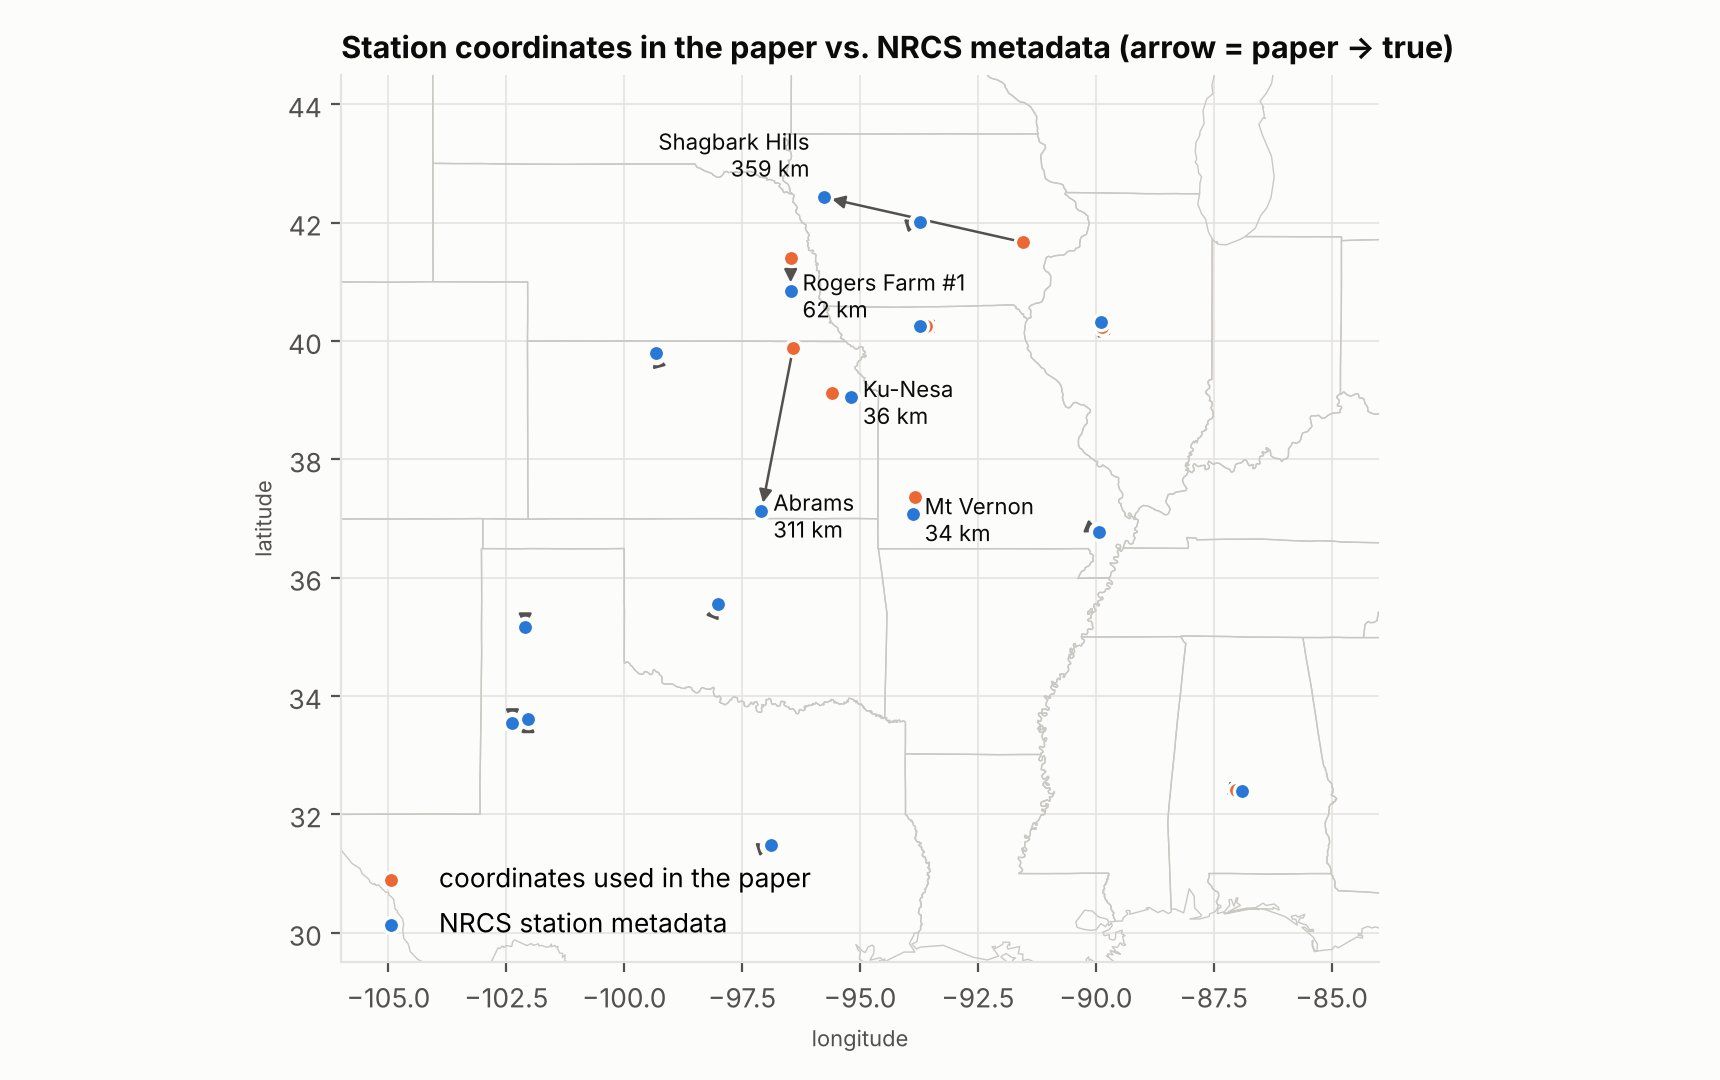

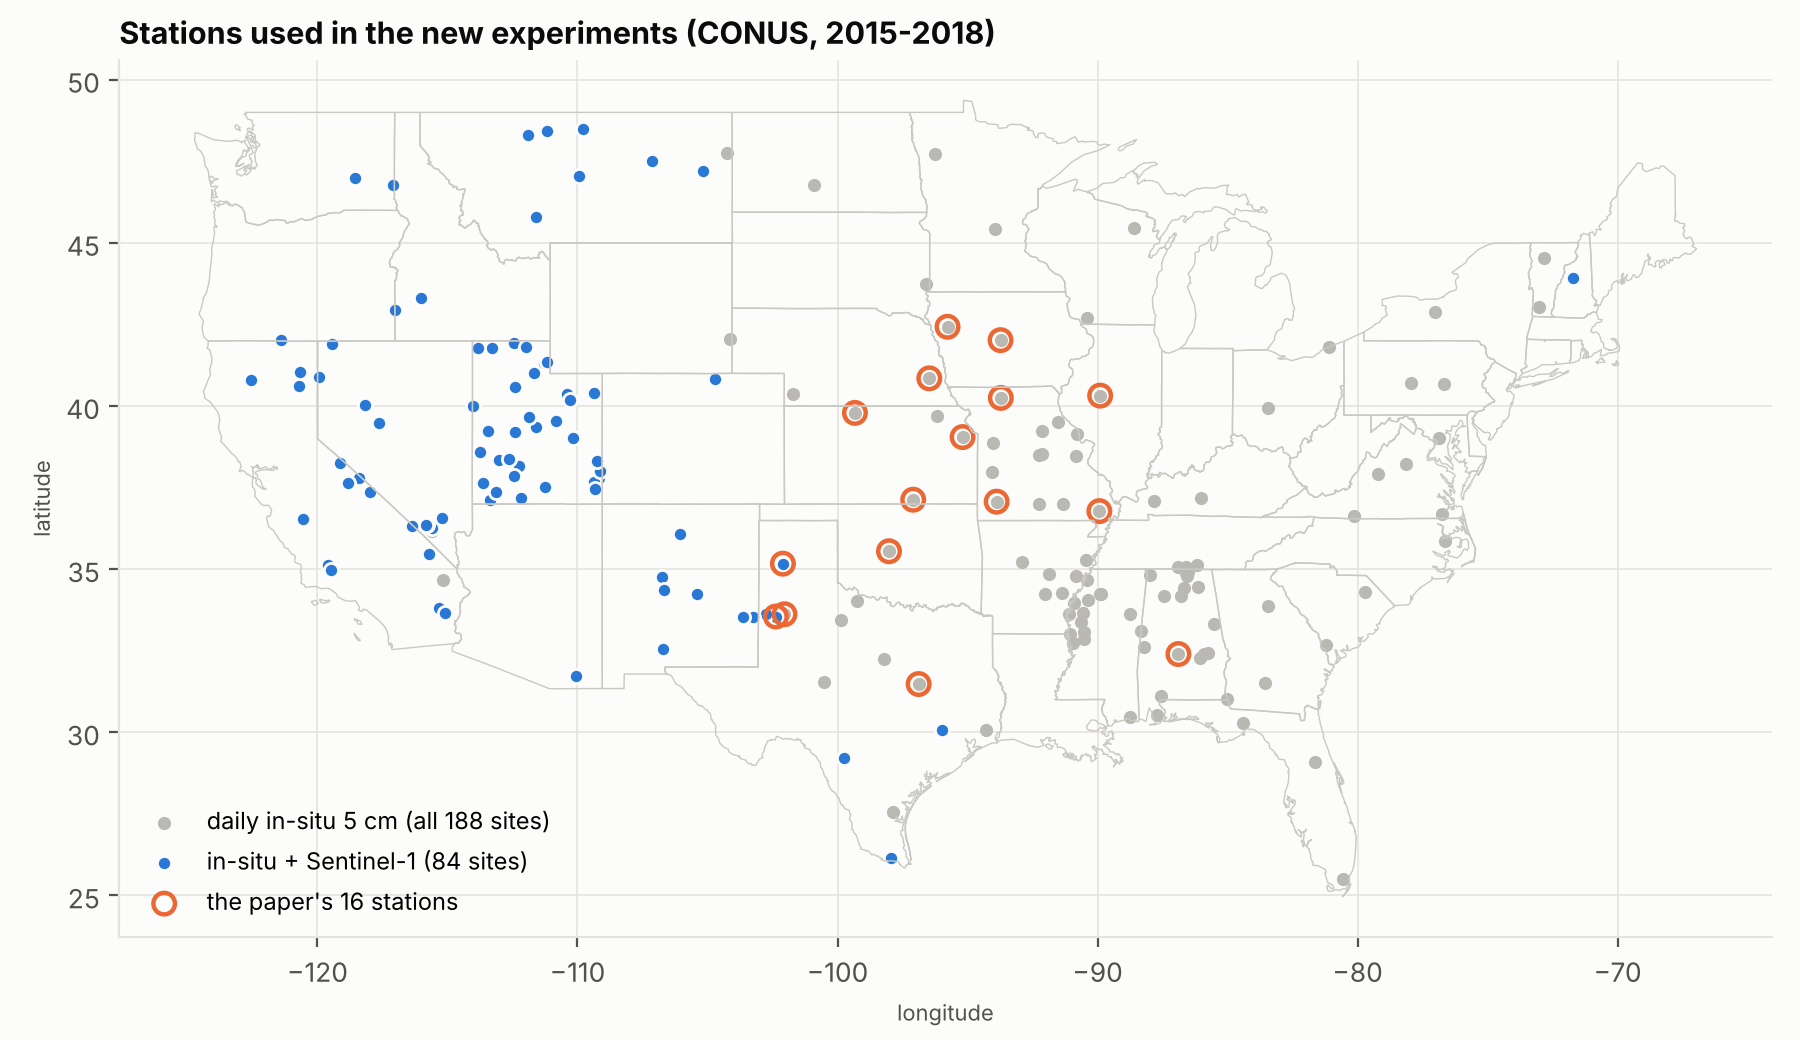

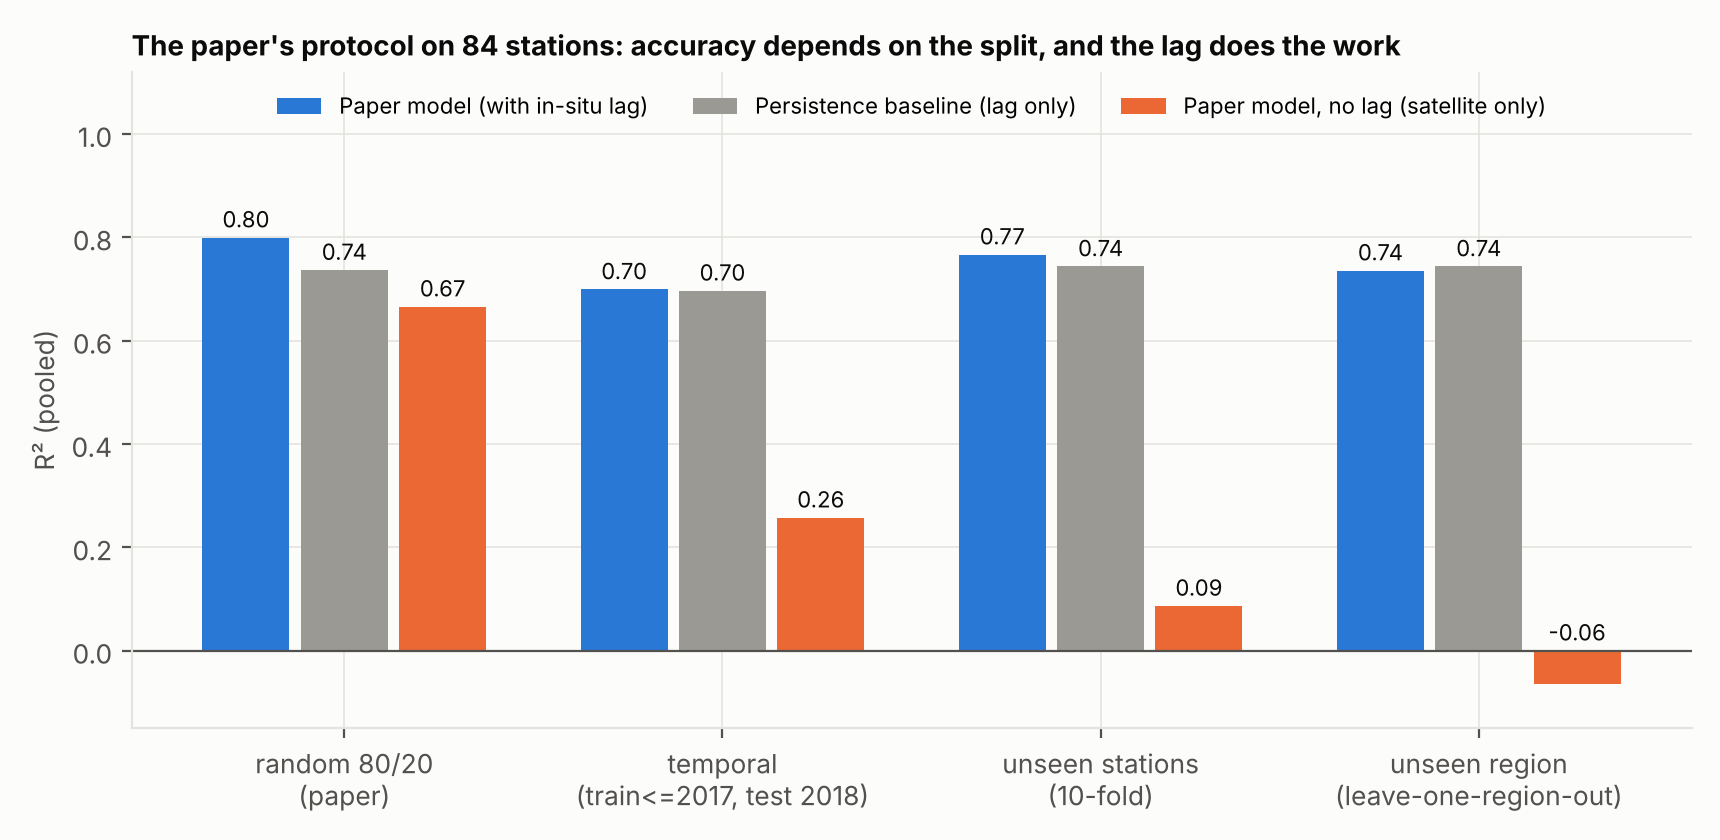

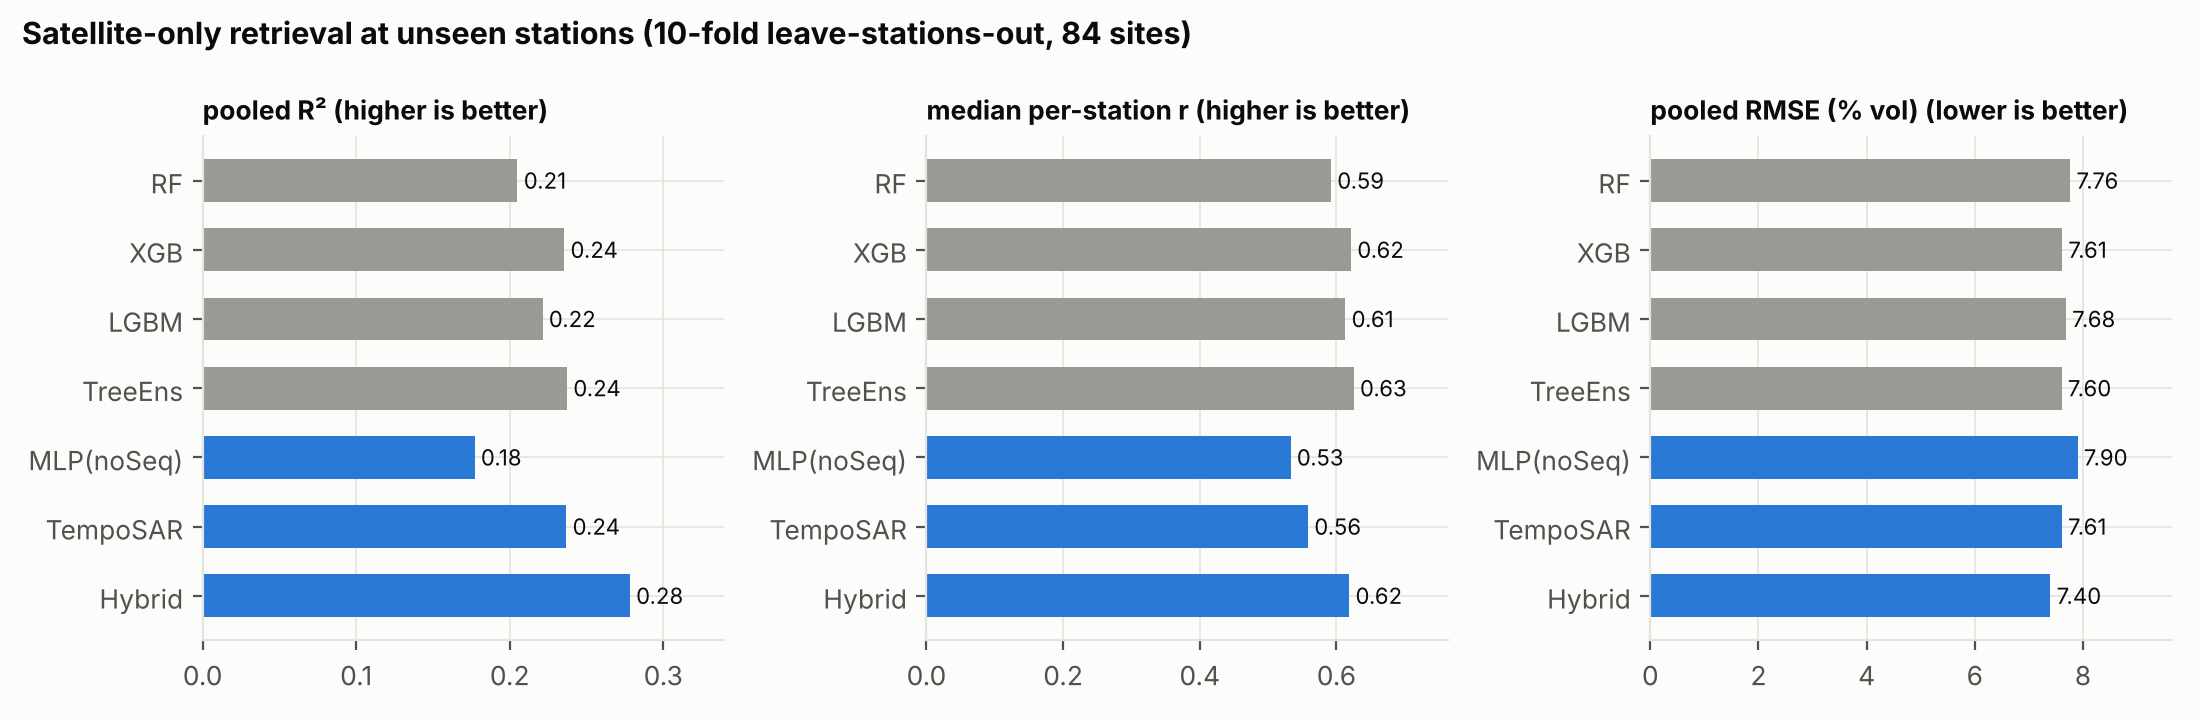

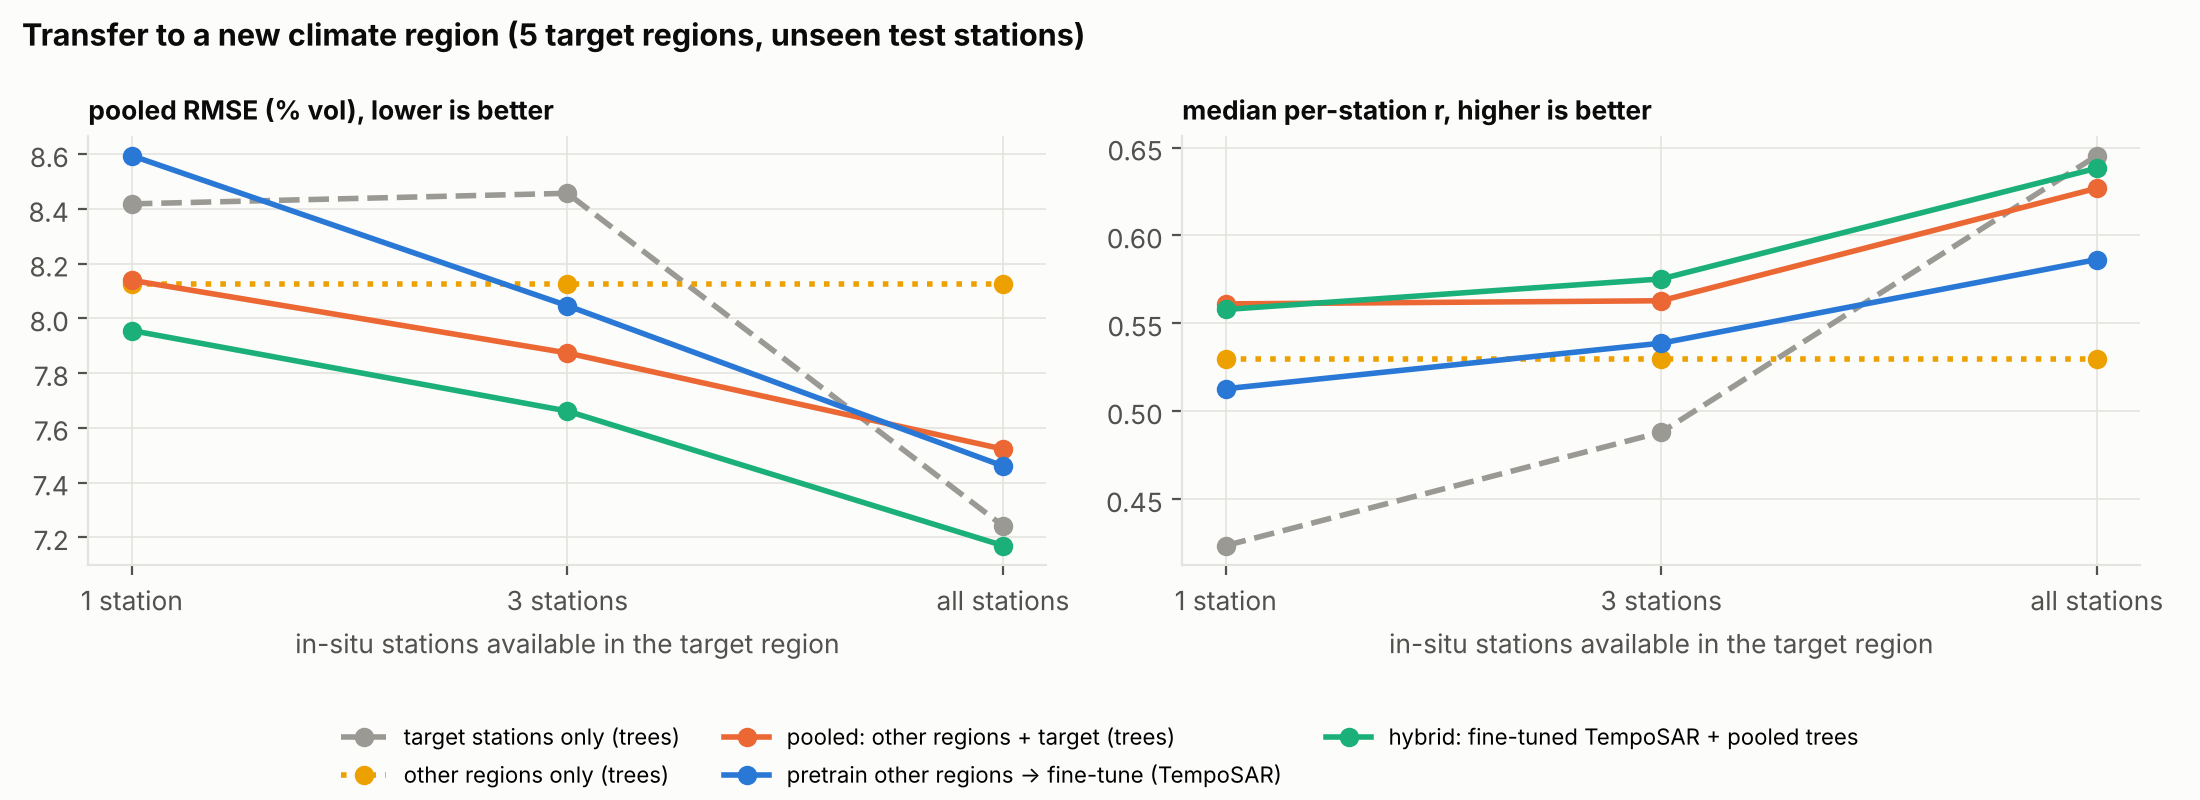

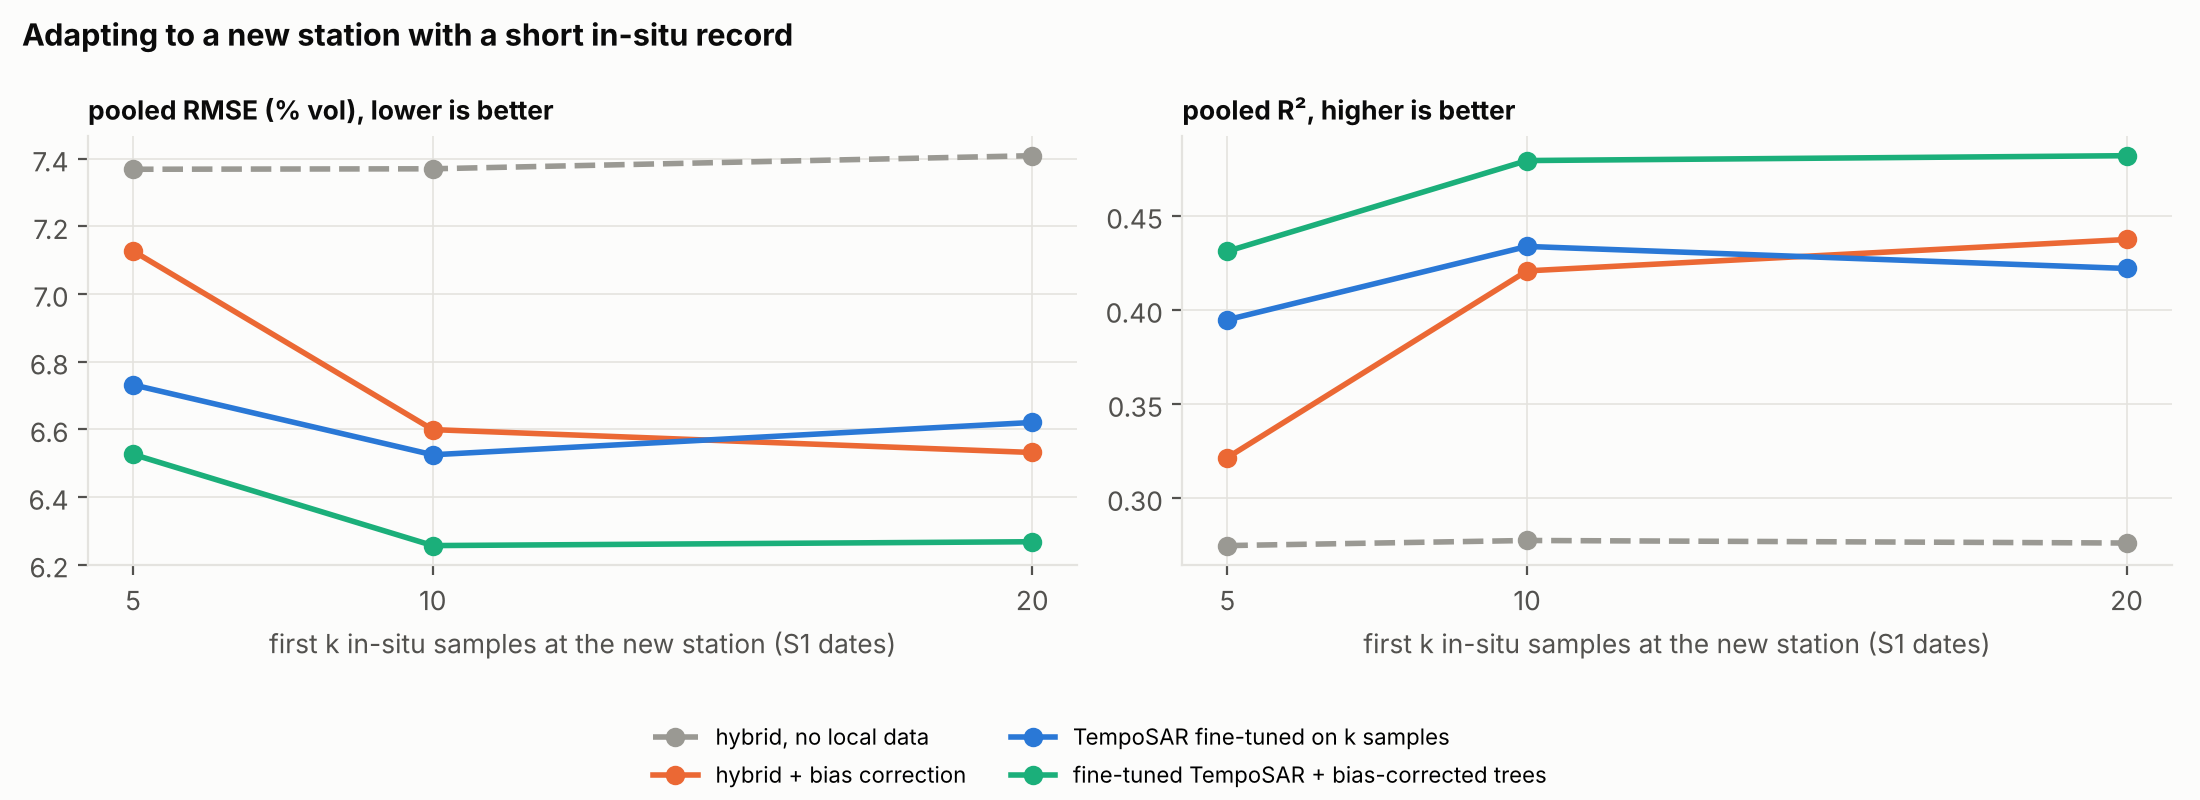

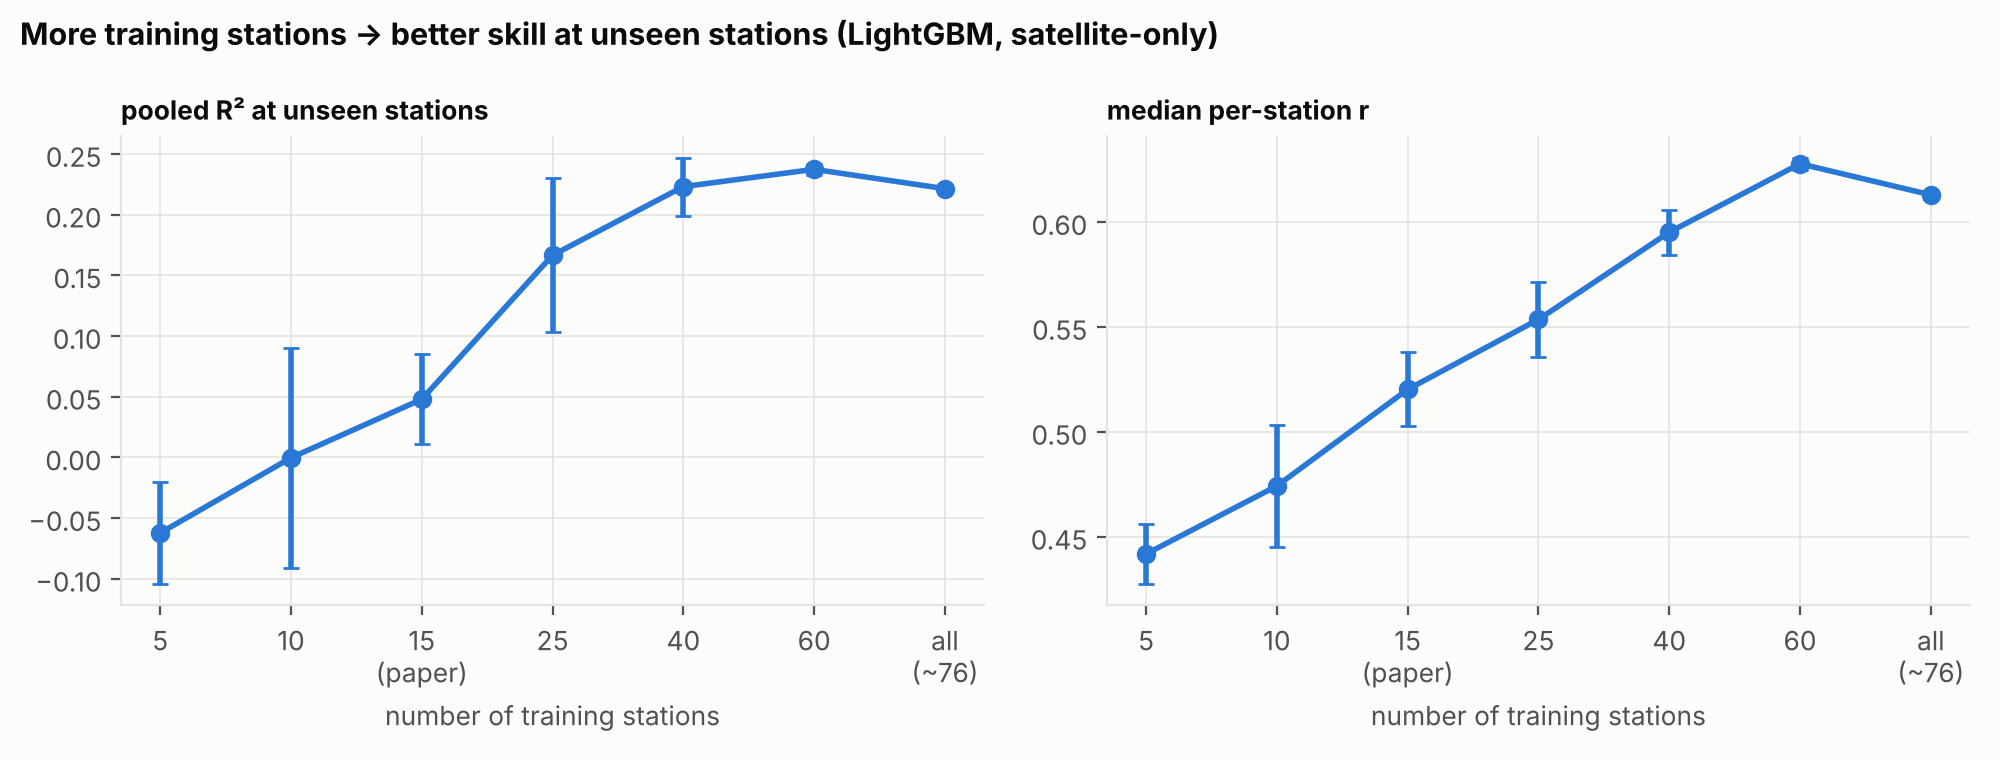

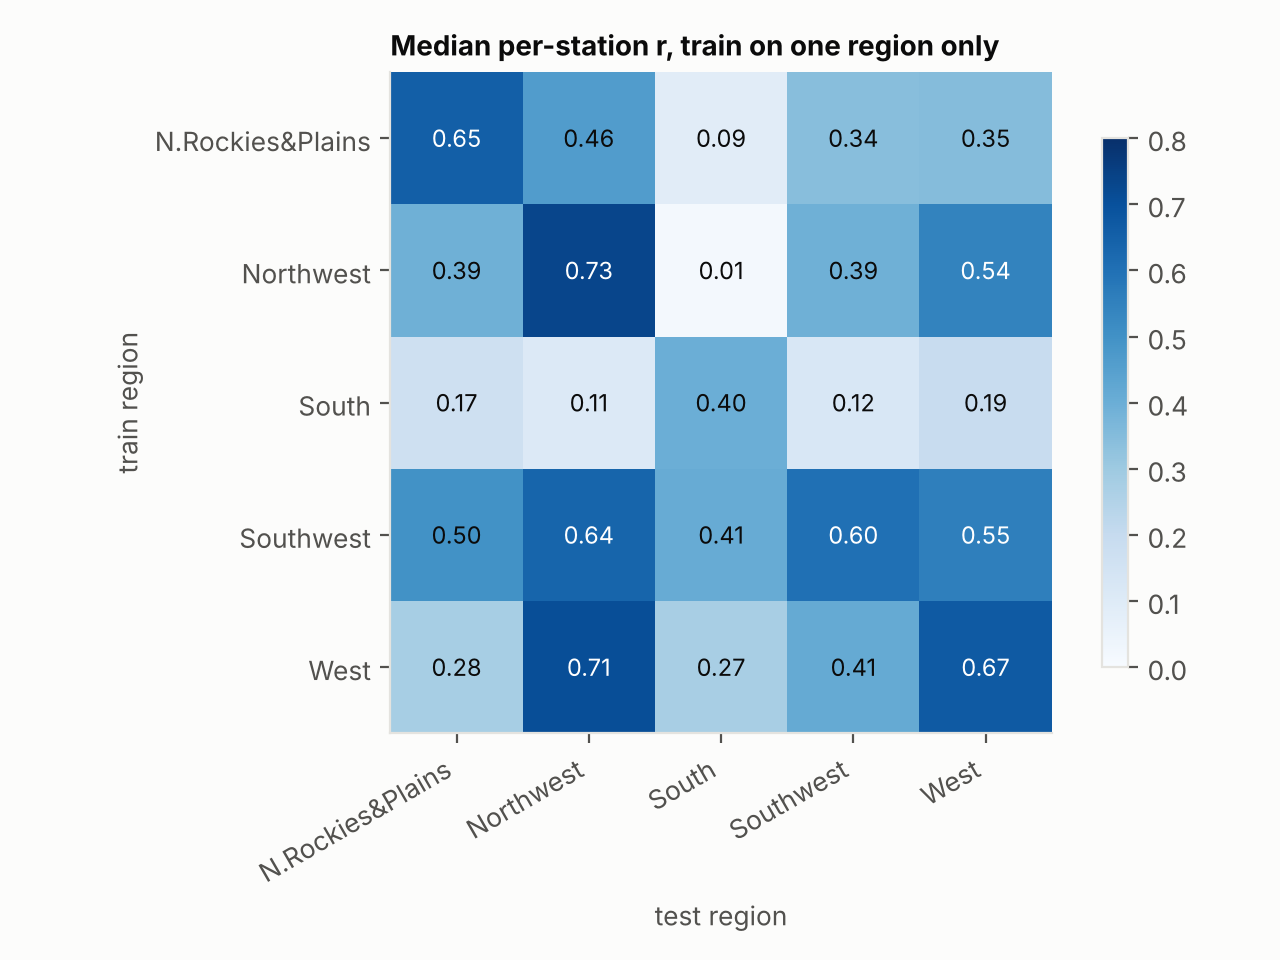

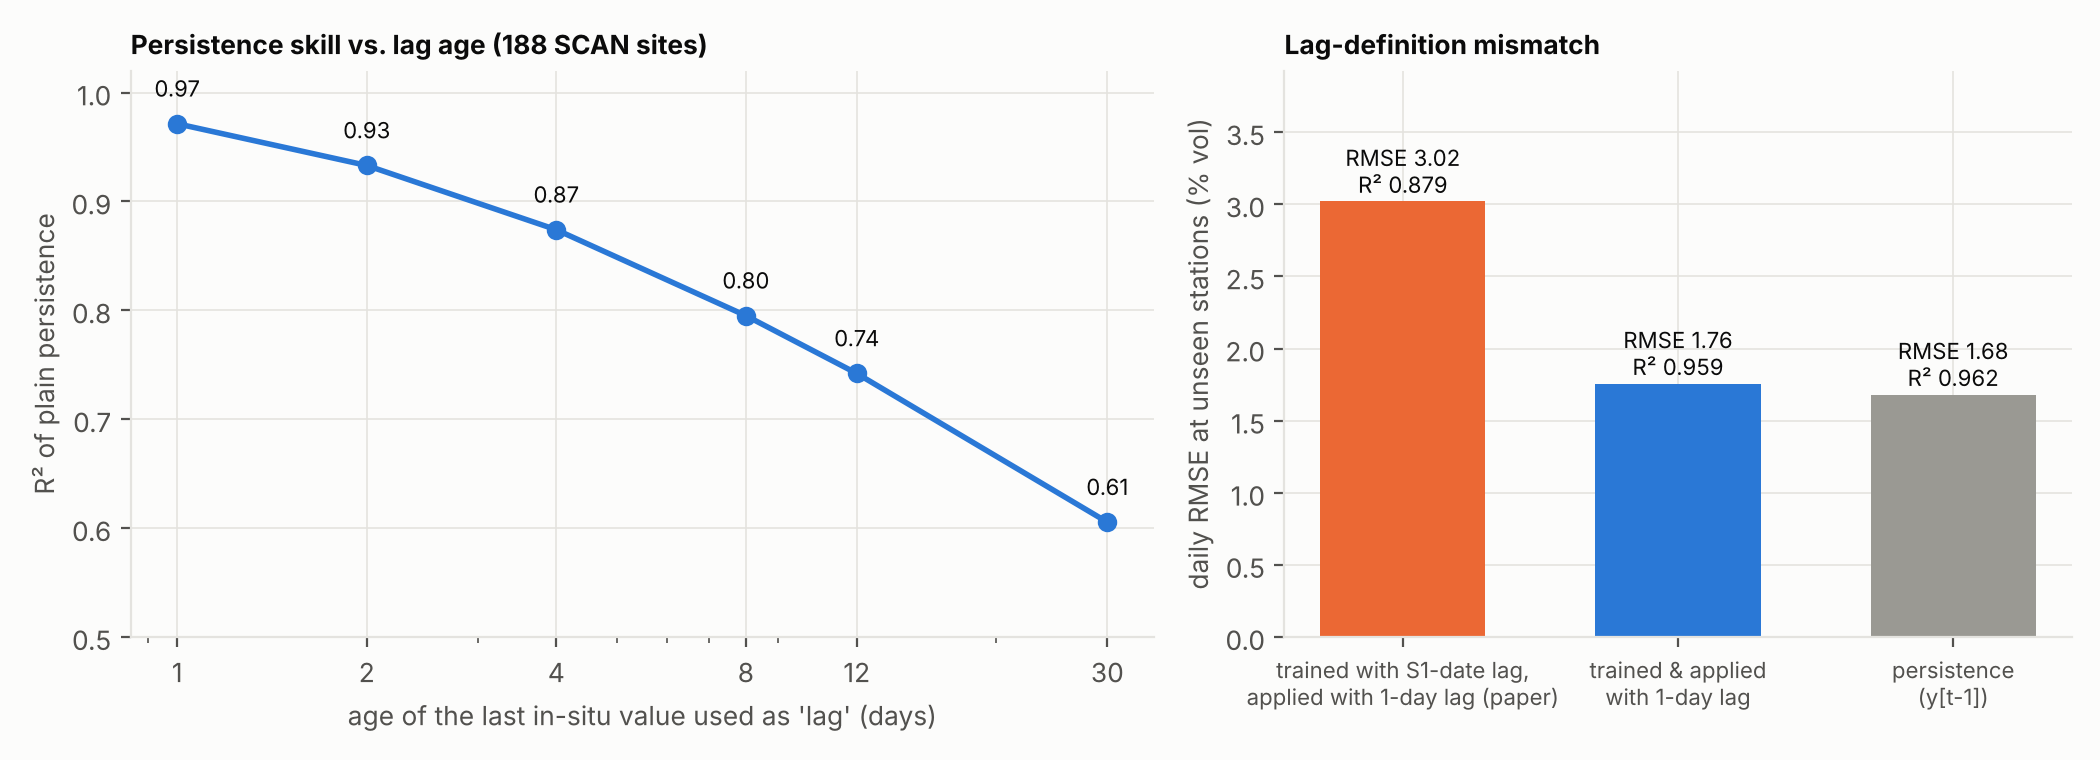

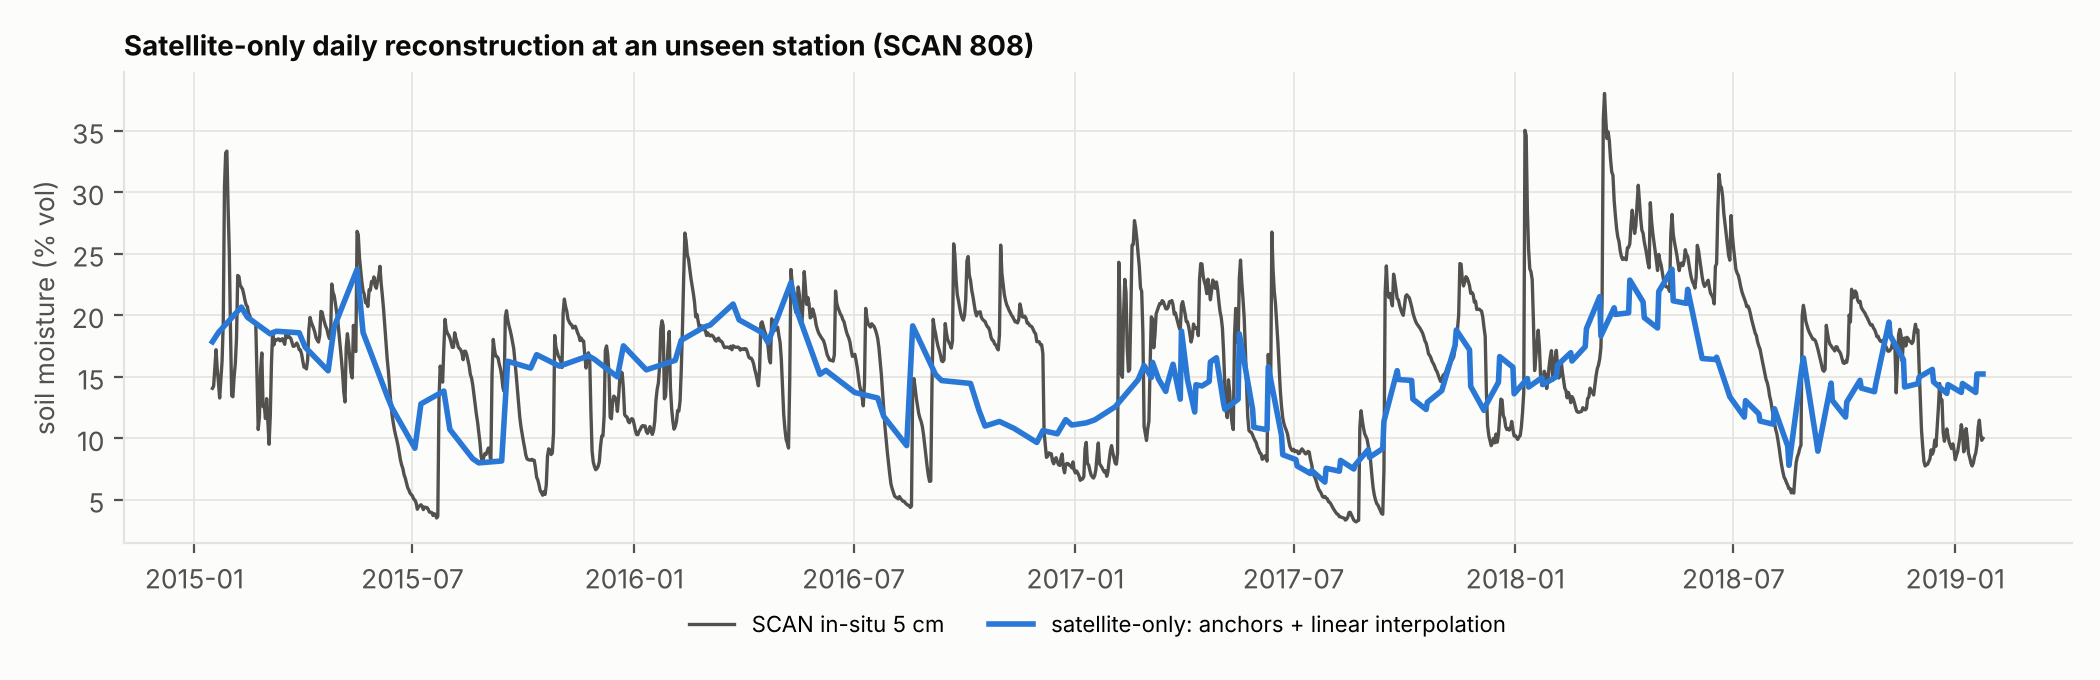

In [11]:
import make_figures as mf
for f in [mf.fig_coordinates, mf.fig_coverage, mf.fig_exp1, mf.fig_exp2a, mf.fig_exp2b, mf.fig_exp2c, mf.fig_exp3, mf.fig_exp4]:
    f()
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('../results/figures/*.png')):
    display(Image(p, width=900))